# Morfologia e contagem — João Paulo

Parte 2: segmentação morfológica e gap-filling para contagem de células nas duas imagens do enunciado. Limiarização, morfologia e contagem implementadas em `src/morfologia.py` e `src/contagem.py`, sem funções prontas de filtragem, morfologia ou rotulagem.

In [1]:
from pathlib import Path
import sys

ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "src").is_dir() and (p / "requirements.txt").is_file()), None)
if ROOT is None:
    raise RuntimeError("Abra o Jupyter dentro da pasta do projeto.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA = ROOT / "data" / "originais"
RESULTADOS = ROOT / "resultados"
SAIDA_CELULAS = RESULTADOS / "celulas"
SAIDA_CELULAS.mkdir(parents=True, exist_ok=True)
print("Projeto:", ROOT.name)

# Configure aqui as entradas ao testar outra imagem.
# objeto_claro: True para objeto claro em fundo escuro; False para objeto escuro em fundo claro.
# sigma = gaussiano leve; raios em pixels do disco do fechamento e da abertura (0 pula a etapa).
IMAGENS = {
    "Imagem 1": dict(arquivo="gap-region-filling.tif", objeto_claro=True, sigma=0, raio_fechamento=2, raio_abertura=2),
    "Imagem 2": dict(arquivo="002f20ad-2ace-499c-9335-c9080bc3e6b5.png", objeto_claro=False, sigma=2, raio_fechamento=2, raio_abertura=4),
}

Projeto: trab-m2.2-pdi


Os testes conferem cada operação em entradas pequenas de resposta conhecida: dilatação e erosão contra a definição com elemento assimétrico, abertura removendo partícula, fechamento unindo fragmentos, preenchimento sem vazar pela diagonal, Otsu e rotulagem em 4 e 8 vizinhos.

In [2]:
import os
import subprocess
# NO_COLOR: o Python 3.14 colore a saída do unittest com códigos ANSI.
r = subprocess.run([sys.executable, "-m", "unittest", "tests.test_morfologia"], capture_output=True, text=True,
                   cwd=ROOT, check=True, env={**os.environ, "NO_COLOR": "1"})
print(r.stderr)

.............
----------------------------------------------------------------------
Ran 13 tests in 0.128s

OK



## 1. Carregar as duas imagens exigidas e converter para cinza

As imagens vêm dos links do enunciado (ver `data/README.md`). A conversão para cinza é feita pela função própria `para_cinza` (pesos BT.601). O carregamento aceita cinza 8 e 16 bits, RGB, RGBA e paleta, porque o processamento pode ser testado com qualquer imagem na apresentação.

O histograma mostra onde o Otsu colocou o limiar. A Imagem 1 já é binária (só 0 e 255): o filtro gaussiano só borraria as bordas, por isso `sigma = 0`. A Imagem 2 é um esfregaço de sangue colorido: hemácias roxas em fundo branco, então o objeto é **escuro** e o centro claro de cada hemácia aparece como buraco.

Imagem 1: (512, 512), Otsu = 0.500


Imagem 2: (1200, 1600, 3), Otsu = 0.771


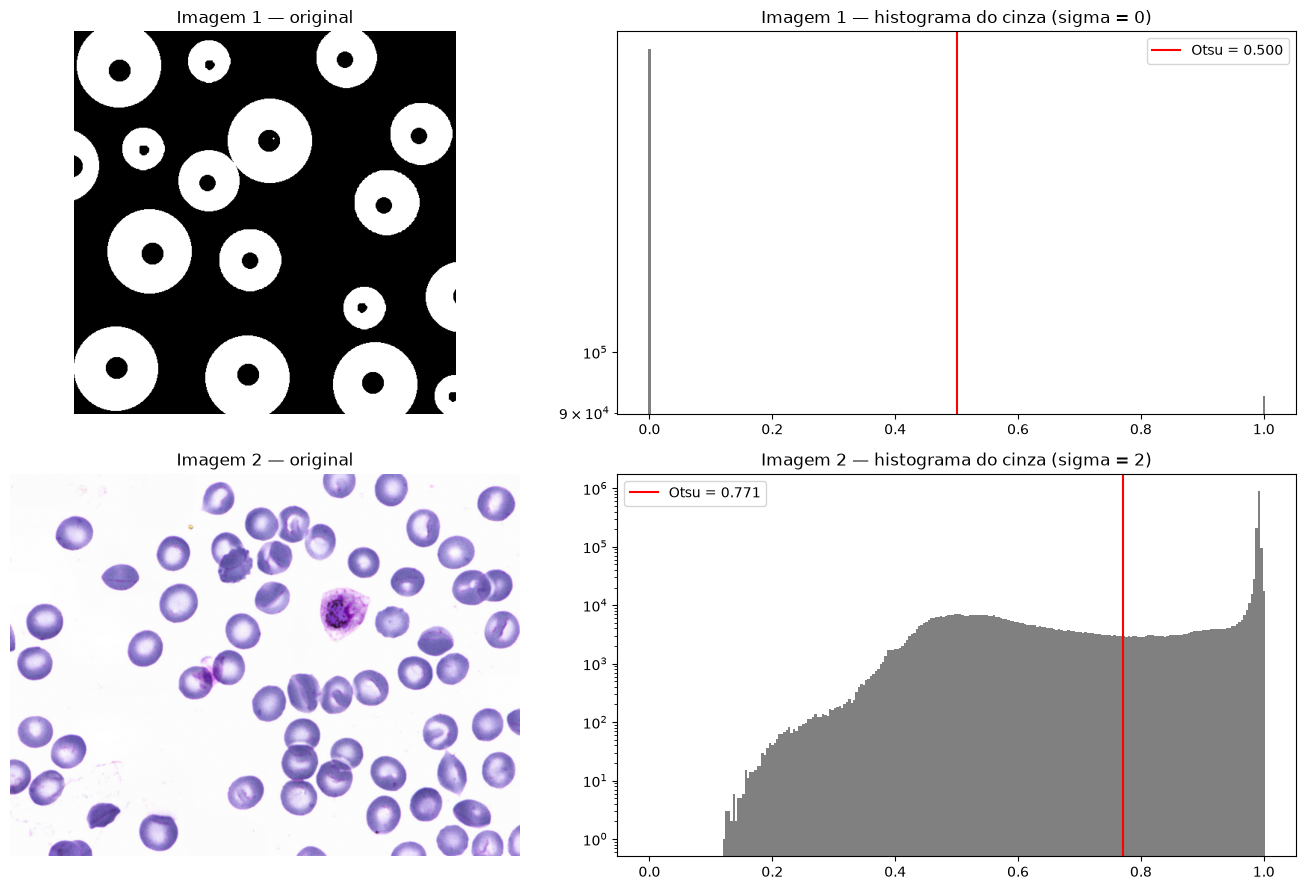

In [3]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from src.segmentacao import para_cinza
from src.morfologia import filtro_gaussiano, histograma, limiar_otsu

def carregar(caminho):
    """Imagem em float [0, 1], cinza ou RGB."""
    with Image.open(caminho) as im:
        if im.mode.startswith("I"):              # cinza 16/32 bits
            a = np.asarray(im, dtype=np.float64)
            return a / a.max() if a.max() > 0 else a
        if im.mode not in ("L", "RGB"):          # RGBA, paleta, 1 bit
            im = im.convert("RGB")
        return np.asarray(im, dtype=np.float64) / 255.0

originais = {nome: carregar(DATA / p["arquivo"]) for nome, p in IMAGENS.items()}

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for i, (nome, img) in enumerate(originais.items()):
    p = IMAGENS[nome]
    suave = filtro_gaussiano(para_cinza(img), p["sigma"])
    t = limiar_otsu(suave)
    print(f"{nome}: {img.shape}, Otsu = {t:.3f}")
    ax[i, 0].imshow(img, cmap="gray"); ax[i, 0].set_title(f"{nome} — original"); ax[i, 0].axis("off")
    ax[i, 1].bar(np.arange(256) / 255, histograma(suave), width=1 / 255, color="gray")
    ax[i, 1].axvline(t, color="red", label=f"Otsu = {t:.3f}")
    ax[i, 1].set_yscale("log"); ax[i, 1].set_title(f"{nome} — histograma do cinza (sigma = {p['sigma']})"); ax[i, 1].legend()
plt.tight_layout()
plt.show()

## 2. Implementar limiarização e analisar falhas

Limiar de Otsu: escolhe o nível que maximiza a variância entre as duas classes. Depois da limiarização aparecem as falhas descritas no enunciado. Em vermelho, os pixels que o preenchimento de buracos vai acrescentar: o centro dos anéis na Imagem 1 e o centro claro das hemácias na Imagem 2. Algumas hemácias têm o centro claro aberto para fora (forma de "C"); como esse buraco toca o fundo, não é buraco para o algoritmo e não é preenchido.

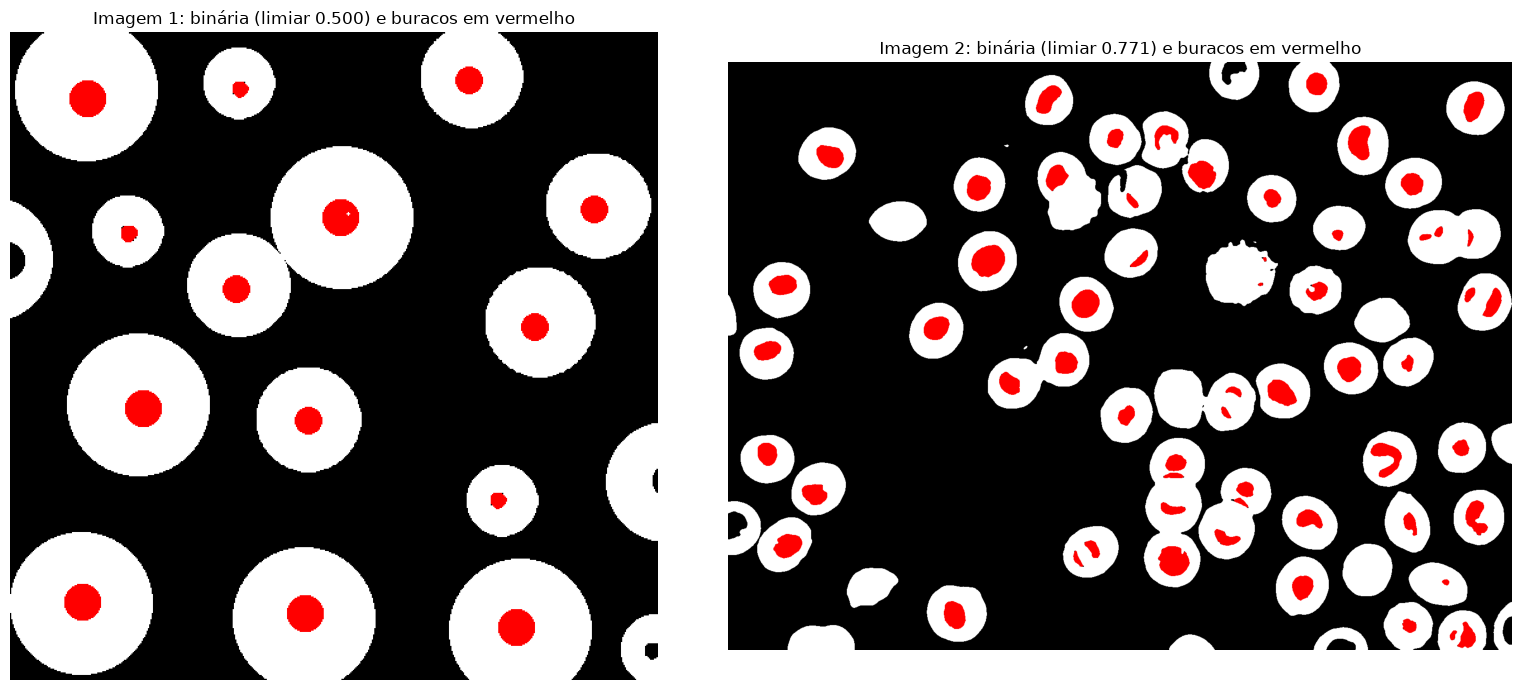

In [4]:
from src.morfologia import segmentar_celulas

etapas = {nome: segmentar_celulas(img, sigma=p["sigma"], objeto_claro=p["objeto_claro"],
                                  raio_fechamento=p["raio_fechamento"], raio_abertura=p["raio_abertura"])
          for (nome, img), p in zip(originais.items(), IMAGENS.values())}

def destacar_buracos(e):
    """Branco = objeto após limiarizar; vermelho = buraco que o preenchimento fecha."""
    rgb = np.zeros(e["binaria"].shape + (3,))
    rgb[e["binaria"]] = 1
    rgb[e["preenchida"] & ~e["fechada"]] = [1, 0, 0]
    return rgb

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a, (nome, e) in zip(ax, etapas.items()):
    a.imshow(destacar_buracos(e)); a.axis("off")
    a.set_title(f"{nome}: binária (limiar {e['limiar']:.3f}) e buracos em vermelho")
plt.tight_layout()
plt.savefig(SAIDA_CELULAS / "falhas_limiarizacao.png", dpi=110, bbox_inches="tight")
plt.show()

## 3. Implementar fechamento, preenchimento e abertura

Ordem do enunciado, com elemento estruturante em **disco** (isotrópico, combina com núcleos arredondados):

1. **Fechamento** (dilatação seguida de erosão): une fragmentos e fecha frestas menores que o disco, o que pode transformar em buraco interno o centro claro aberto ("C") de algumas hemácias.
2. **Preenchimento de buracos**: inunda o fundo a partir da borda da imagem, com dilatação condicional em 4 vizinhos; o que a água não alcança é buraco. O par 4 (fundo) / 8 (objeto) impede a água de atravessar uma quina diagonal por onde o objeto está conectado.
3. **Abertura** (erosão seguida de dilatação): remove partículas menores que o disco e devolve aos objetos restantes quase o tamanho original.

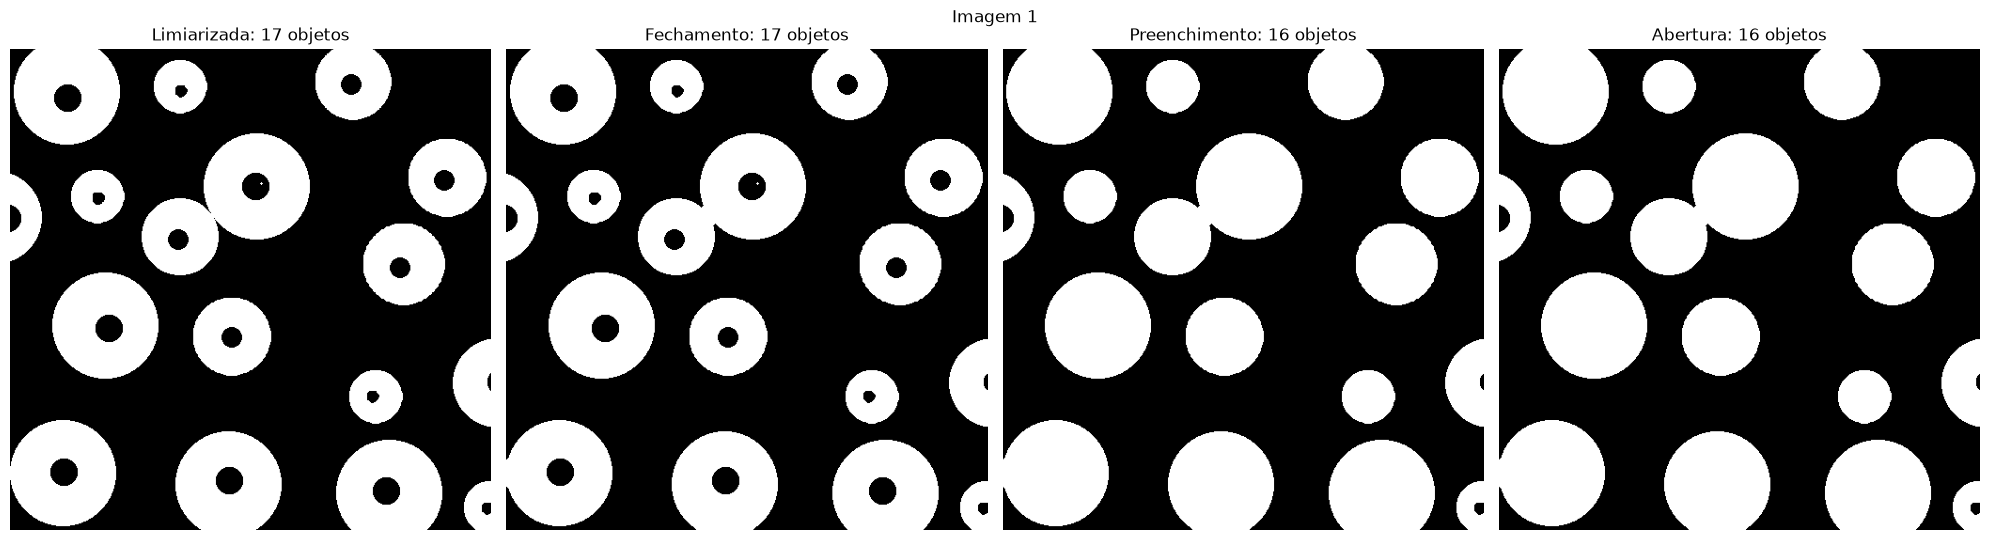

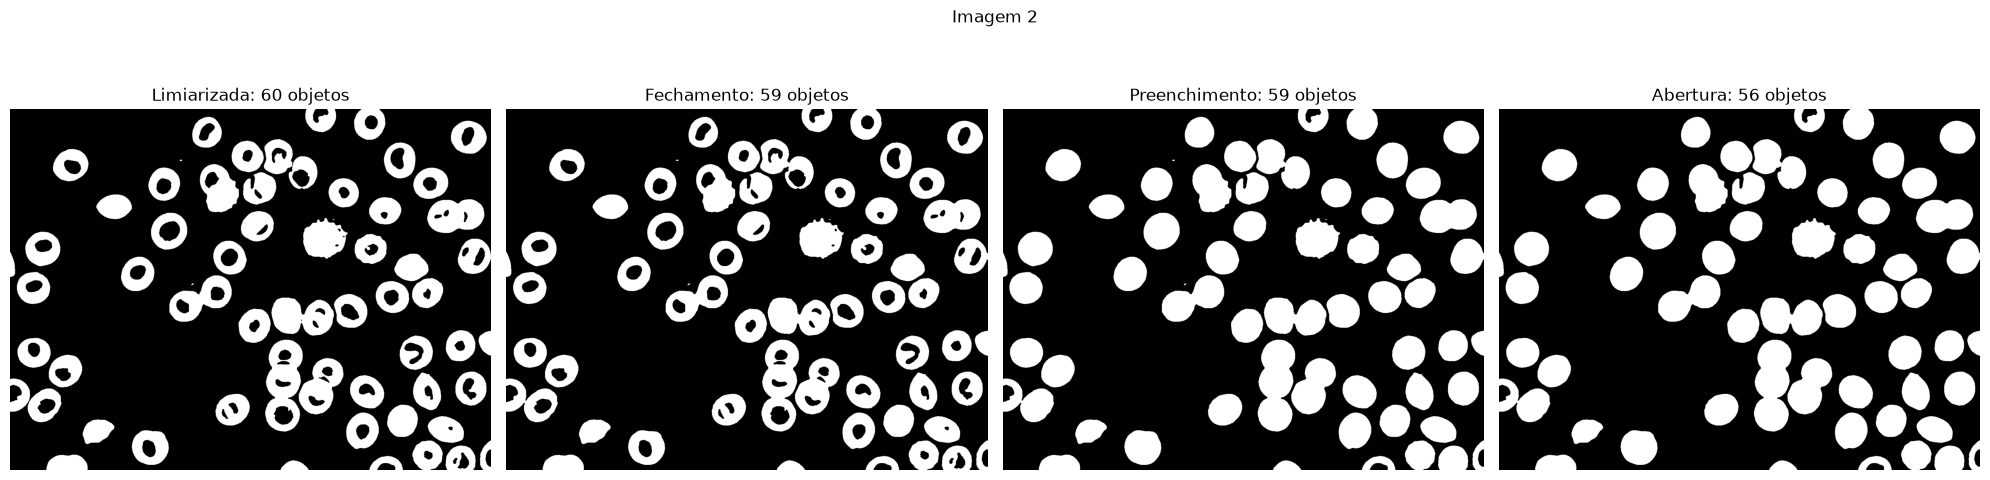

In [5]:
from src.contagem import contar_objetos

NOMES_ETAPAS = {"binaria": "Limiarizada", "fechada": "Fechamento", "preenchida": "Preenchimento", "aberta": "Abertura"}
for nome, e in etapas.items():
    fig, ax = plt.subplots(1, 4, figsize=(20, 5.5))
    for a, (chave, titulo) in zip(ax, NOMES_ETAPAS.items()):
        n, _ = contar_objetos(e[chave])
        a.imshow(e[chave], cmap="gray"); a.set_title(f"{titulo}: {n} objetos"); a.axis("off")
    fig.suptitle(nome)
    plt.tight_layout()
    plt.savefig(SAIDA_CELULAS / f"etapas_{nome.lower().replace(' ', '')}.png", dpi=110, bbox_inches="tight")
    plt.show()

## 4. Implementar componentes conectados e comparar contagens por etapa

Contagem própria (`src/contagem.py`): percorre a imagem em ordem de leitura; ao achar um pixel de objeto sem rótulo, abre um rótulo novo e o espalha por busca em largura aos vizinhos de objeto (8-vizinhança). Cada pixel entra na fila uma vez, então o custo é linear. O número de rótulos é o número de objetos.

A tabela mostra a contagem em cada etapa e quantos pixels de objeto existem. Para estimar células fundidas, contamos os objetos finais com mais de 1,5 vez a área mediana. O critério só faz sentido quando as células têm tamanho parecido, como na Imagem 2; na Imagem 1 os anéis têm tamanhos diferentes por construção.

In [6]:
import csv
from src.contagem import areas, comparar_etapas

tabela = []
for nome, e in etapas.items():
    linhas = comparar_etapas({titulo: e[chave] for chave, titulo in NOMES_ETAPAS.items()})
    for l in linhas:
        tabela.append(dict(imagem=nome, **l))
    _, rot = contar_objetos(e["aberta"])
    a = areas(rot)
    grandes = int((a > 1.5 * np.median(a)).sum())
    print(f"{nome}: área mediana {np.median(a):.0f} px; {grandes} objetos com mais de 1,5x a mediana")

print(f"\n{'Imagem':9} {'Etapa':14} {'Objetos':>7} {'Variação':>8} {'Pixels de objeto':>17}")
for l in tabela:
    var = "" if l["variacao"] is None else f"{l['variacao']:+d}"
    print(f"{l['imagem']:9} {l['etapa']:14} {l['objetos']:7d} {var:>8} {l['pixels_objeto']:17d}")
with open(SAIDA_CELULAS / "contagem_etapas.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=tabela[0].keys())
    w.writeheader(); w.writerows(tabela)

Imagem 1: área mediana 5412 px; 6 objetos com mais de 1,5x a mediana


Imagem 2: área mediana 9252 px; 8 objetos com mais de 1,5x a mediana

Imagem    Etapa          Objetos Variação  Pixels de objeto
Imagem 1  Limiarizada         17                      92581
Imagem 1  Fechamento          17       +0             92653
Imagem 1  Preenchimento       16       -1             98963
Imagem 1  Abertura            16       +0             98963
Imagem 2  Limiarizada         60                     466102
Imagem 2  Fechamento          59       -1            466488
Imagem 2  Preenchimento       59       +0            540076
Imagem 2  Abertura            56       -3            539834


## 5. Exibir original, binária, processada e rótulos coloridos

Cada objeto recebe uma cor (matizes espaçados pelo ângulo áureo, então vizinhos na ordem de leitura ficam com cores bem diferentes) e o seu número no centroide. Uma mesma cor cobrindo duas células indica células fundidas.

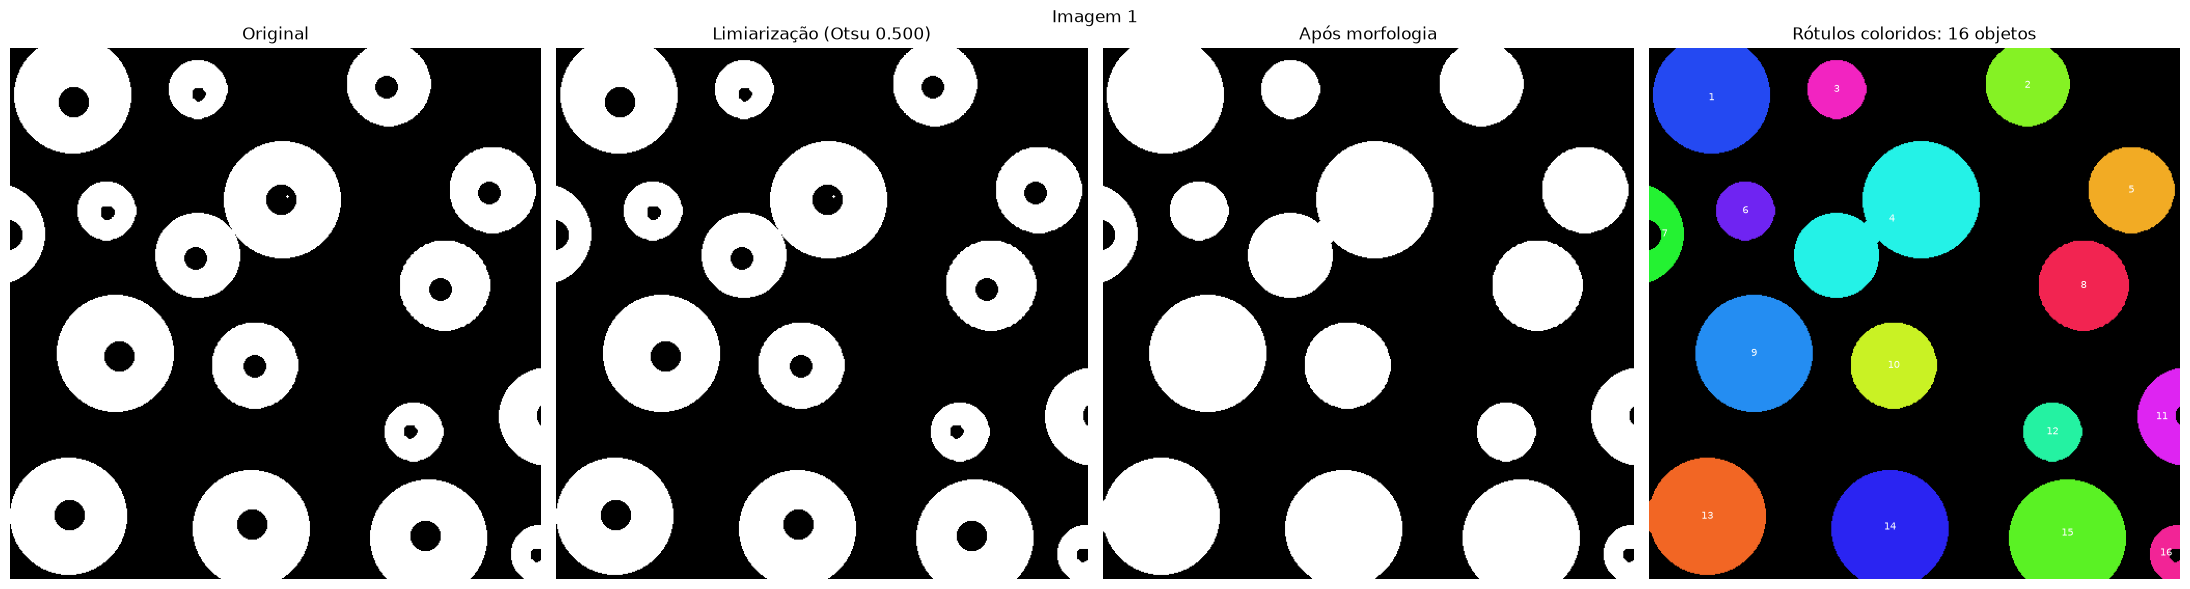

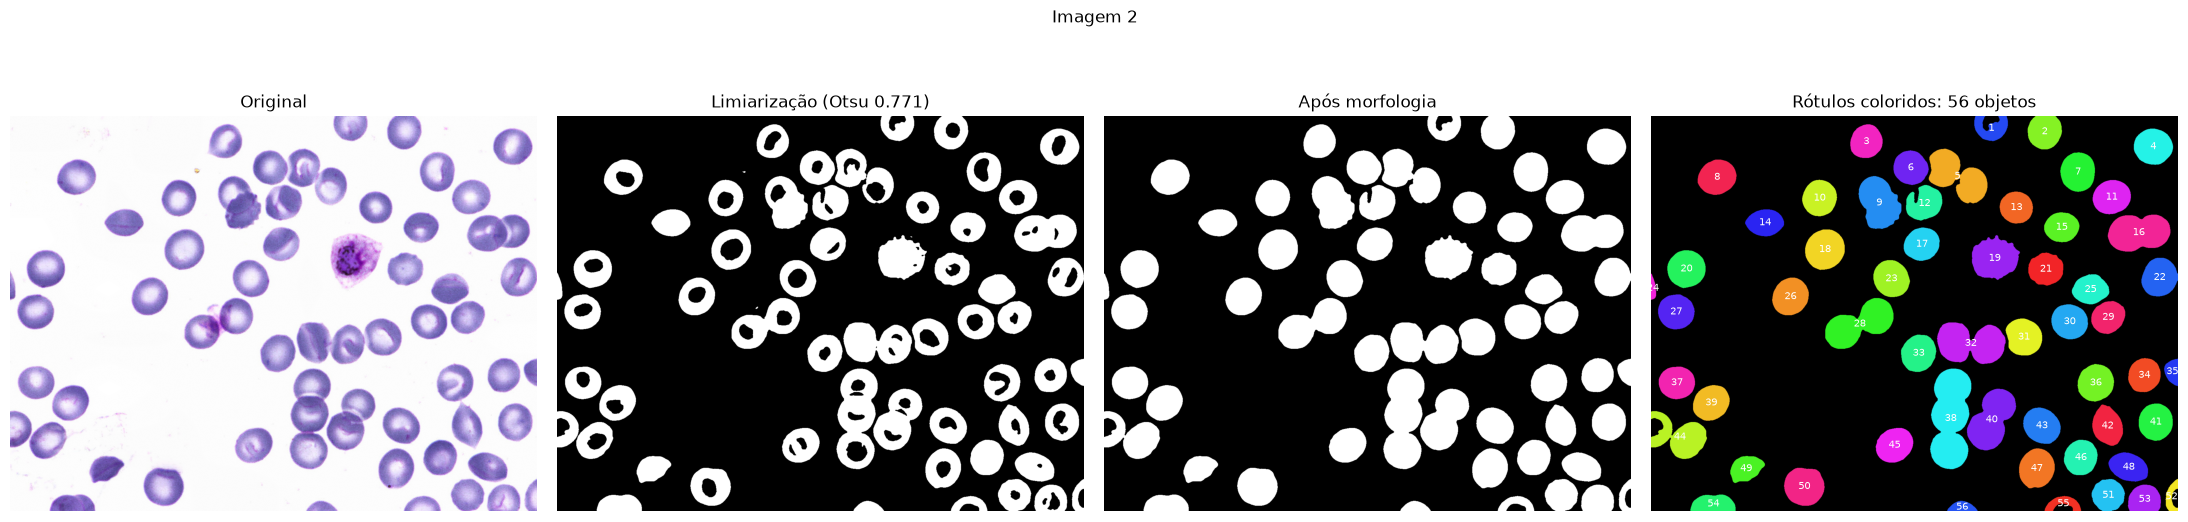

In [7]:
from src.contagem import colorir_rotulos, medidas

for nome, e in etapas.items():
    n, rot = contar_objetos(e["aberta"])
    fig, ax = plt.subplots(1, 4, figsize=(22, 6))
    ax[0].imshow(originais[nome], cmap="gray"); ax[0].set_title("Original")
    ax[1].imshow(e["binaria"], cmap="gray"); ax[1].set_title(f"Limiarização (Otsu {e['limiar']:.3f})")
    ax[2].imshow(e["aberta"], cmap="gray"); ax[2].set_title("Após morfologia")
    ax[3].imshow(colorir_rotulos(rot)); ax[3].set_title(f"Rótulos coloridos: {n} objetos")
    for obj in medidas(rot):
        y, x = obj["centroide"]
        ax[3].text(x, y, obj["rotulo"], color="white", fontsize=7, ha="center", va="center")
    for a in ax: a.axis("off")
    fig.suptitle(nome)
    plt.tight_layout()
    plt.savefig(SAIDA_CELULAS / f"resultado_{nome.lower().replace(' ', '')}.png", dpi=110, bbox_inches="tight")
    plt.show()

## 6. Parâmetros, resultados e limitações

| Parâmetro | Imagem 1 | Imagem 2 | Por quê |
|---|---|---|---|
| Objeto | claro | escuro | anéis brancos em fundo preto; hemácias roxas em fundo branco |
| Gaussiano (sigma) | 0 | 2 | a Imagem 1 já é binária; na 2 suaviza a textura dentro das hemácias |
| Limiar | Otsu | Otsu | dois grupos bem separados no histograma |
| Fechamento | disco r = 2 | disco r = 2 | fecha frestas pequenas; r = 6 já fundia hemácias (60 → 51 objetos) |
| Abertura | disco r = 2 | disco r = 4 | remove partículas; na Imagem 2 há resíduos de corante |
| Conectividade | 8 (objeto), 4 (fundo) | 8 (objeto), 4 (fundo) | par complementar: o fundo não vaza por quinas diagonais |

**Imagem 1.** São 17 componentes depois da limiarização. Um deles é um ponto de 5 pixels **dentro do buraco** de um anel: conta como objeto falso até o preenchimento, que o incorpora ao anel. Por isso a contagem cai de 17 para 16 só no gap-filling, que é exatamente a comparação pedida no enunciado. Os anéis cortados pela borda da imagem continuam ocos, porque o seu buraco toca a borda e, para o algoritmo, é fundo. Dois anéis que se tocam contam como um único objeto: a morfologia sozinha não separa objetos encostados.

**Imagem 2.** O preenchimento acrescenta dezenas de milhares de pixels (o centro claro das hemácias), mas quase não muda a contagem: um anel já era contado como um objeto. O ganho do gap-filling aqui está na forma e na área de cada célula, não no número. O erro principal da contagem são as **hemácias encostadas**, que viram um objeto só: os objetos com mais de 1,5 vez a área mediana indicam esses aglomerados. Fechamento maior pioraria isso. Separá-las exigiria Watershed na transformada de distância, que o enunciado deixa fora desta parte. A célula grande e escura no centro (leucócito ou célula parasitada) conta como mais um objeto.

**Limitações.** Os raios foram escolhidos por inspeção visual nestas duas imagens; não há contagem manual de referência para medir o erro. Células cortadas pela borda contam como objetos inteiros.